# Лабораторная работа 5. Модели классификации и их интерпретация

**Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ**
Дисциплина «Разведочный анализ и алгоритмы классификации»

**Этап CRISP-DM:** Modeling → Evaluation. Датасет — Online Shoppers Purchasing Intention, признаки подготовлены конвейером из lab4 (`src/features.py`).

**Цель:** построить несколько моделей классификации из лекций 3–4, сравнить их корректно для несбалансированных классов, объяснить словами, хорошее ли получилось качество, и интерпретировать как модель в целом, так и отдельные прогнозы.

**Задачи:**
1. Выбрать метрики и схему валидации.
2. Обучить и настроить модели: kNN, логистическая регрессия, решающее дерево, случайный лес, SVM, градиентный бустинг (CatBoost); сравнить способы работы с дисбалансом (веса классов, SMOTE).
3. Оценить лучшие модели на отложенной тестовой выборке, выбрать порог отсечения.
4. Интерпретировать качество (что значат метрики для магазина).
5. Интерпретировать модель: коэффициенты, важность признаков, SHAP; разобрать отдельные прогнозы.
6. Проверить зависимость модели от признака `PageValues`.

## 1. Метрики и схема валидации
* Классы несбалансированы (15,5 % покупок), поэтому **accuracy не годится как главная метрика**: константный ответ «нет покупки» даёт 84,5 %.
* **ROC-AUC** — вероятность того, что случайная сессия с покупкой получит от модели больший балл, чем случайная сессия без покупки; не зависит от порога. 0,5 — случайное угадывание.
* **PR-AUC (average precision)** — площадь под кривой «точность — полнота»; в отличие от ROC-AUC, чувствительна к дисбалансу. Базовый уровень равен доле положительного класса, т. е. 0,155.
* При пороге: **precision** (какая доля сессий, отмеченных моделью как «покупка», действительно с покупкой), **recall** (какую долю всех покупок модель нашла), **F1** — их гармоническое среднее, **balanced accuracy** — среднее полноты по двум классам.
* Работа с дисбалансом — в сетках гиперпараметров: `class_weight="balanced"` (sklearn), `scale_pos_weight` = 5,46 (CatBoost: вес класса «покупка» равен отношению классов) и отдельно SMOTE для логистической регрессии.
* Схема: train (80 %) → подбор гиперпараметров на **5-кратной стратифицированной кросс-валидации** (одни и те же фолды для всех моделей); test (20 %) — только для финальной оценки. Критерий выбора гиперпараметров — PR-AUC.

In [1]:
import sys, time, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from matplotlib.ticker import PercentFormatter

from sklearn import set_config
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, accuracy_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from catboost import CatBoostClassifier

from src.data import load, NUMERIC, NOMINAL, TARGET
from src.features import make_preprocessor, split, pretty_names, encode_for_trees, RANDOM_STATE
from src.model import make_final_model, FINAL_PARAMS, choose_threshold
from src import viz
set_config(display="text")
viz.setup()
pd.set_option("display.width", 160)

df = load()
X_train, X_test, y_train, y_test = split(df)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "precision": "precision",
           "recall": "recall", "bal_acc": "balanced_accuracy", "accuracy": "accuracy", "brier": "neg_brier_score"}
print("train:", X_train.shape, "test:", X_test.shape, "| доля покупок в train:", round(y_train.mean(), 4))

train: (9864, 17) test: (2466, 17) | доля покупок в train: 0.1547


## 2. Обучение и подбор гиперпараметров
Для каждой модели — небольшая сетка гиперпараметров (вычисления ограничены, `n_jobs=1`). Модели, чувствительные к масштабу (kNN, логистическая регрессия, SVM), получают признаки после `log1p` и стандартизации; деревья и бустинг — one-hot без масштабирования. У части моделей в сетку включён параметр `class_weight="balanced"` — **cost-sensitive** обучение из лекции: ошибка на редком классе штрафуется сильнее.

In [2]:
lin, tree = (lambda: make_preprocessor("linear")), (lambda: make_preprocessor("tree"))
experiments = {
    "Dummy (самый частый класс)": (Pipeline([("pre", tree()), ("clf", DummyClassifier(strategy="prior"))]), {}),
    "kNN": (Pipeline([("pre", lin()), ("clf", KNeighborsClassifier())]),
            {"clf__n_neighbors": [15, 51, 101], "clf__weights": ["uniform", "distance"]}),
    "Логистическая регрессия": (Pipeline([("pre", lin()), ("clf", LogisticRegression(max_iter=3000))]),
            {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "Логистическая регрессия + SMOTE": (ImbPipeline([("pre", lin()), ("smote", SMOTE(random_state=RANDOM_STATE)),
                                                      ("clf", LogisticRegression(max_iter=3000))]),
            {"clf__C": [0.1, 1]}),
    "Решающее дерево": (Pipeline([("pre", tree()), ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
            {"clf__max_depth": [3, 5, 8, 12], "clf__min_samples_leaf": [1, 50], "clf__class_weight": [None, "balanced"]}),
    "Случайный лес": (Pipeline([("pre", tree()), ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=1,
                                                                                  random_state=RANDOM_STATE))]),
            {"clf__max_depth": [12, None], "clf__class_weight": [None, "balanced_subsample"]}),
    "SVM (RBF)": (Pipeline([("pre", lin()), ("clf", SVC(kernel="rbf", gamma="scale", random_state=RANDOM_STATE))]),
            {"clf__C": [1], "clf__class_weight": [None, "balanced"]}),
    "CatBoost": (Pipeline([("pre", tree()), ("clf", CatBoostClassifier(iterations=500, learning_rate=0.05, verbose=0,
                                                                         thread_count=1, random_seed=RANDOM_STATE, allow_writing_files=False))]),
            {"clf__depth": [4, 6], "clf__scale_pos_weight": [1.0, round(float((y_train == 0).sum() / y_train.sum()), 2)]}),
}

searches, rows = {}, []
for name, (pipe, grid) in experiments.items():
    t0 = time.time()
    # у SVC нет predict_proba, поэтому для него не считаем Brier score
    scoring = {k: v for k, v in SCORING.items() if k != "brier" or hasattr(pipe[-1], "predict_proba")}
    gs = GridSearchCV(pipe, grid or {"clf__strategy": ["prior"]}, cv=cv, scoring=scoring, refit="pr_auc", n_jobs=1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    i = gs.best_index_
    r = {"модель": name}
    for k in SCORING:
        r[k] = gs.cv_results_[f"mean_test_{k}"][i] if k in scoring else np.nan
    r["brier"] = -r["brier"]  # sklearn возвращает Brier со знаком минус
    r["σ(pr_auc)"] = gs.cv_results_["std_test_pr_auc"][i]
    r["лучшие параметры"] = ", ".join(f"{k.split('__')[1]}={v}" for k, v in gs.best_params_.items()) if grid else "—"
    r["время, с"] = round(time.time() - t0, 1)
    rows.append(r)
    print(f"{name:35s} PR-AUC={r['pr_auc']:.3f} ROC-AUC={r['roc_auc']:.3f}  ({r['время, с']} с)")
cv_table = pd.DataFrame(rows).set_index("модель")

Dummy (самый частый класс)          PR-AUC=0.155 ROC-AUC=0.500  (1.5 с)


kNN                                 PR-AUC=0.722 ROC-AUC=0.918  (99.9 с)


Логистическая регрессия             PR-AUC=0.691 ROC-AUC=0.916  (74.1 с)


Логистическая регрессия + SMOTE     PR-AUC=0.670 ROC-AUC=0.912  (108.5 с)


Решающее дерево                     PR-AUC=0.716 ROC-AUC=0.924  (32.6 с)


Случайный лес                       PR-AUC=0.748 ROC-AUC=0.929  (138.6 с)


SVM (RBF)                           PR-AUC=0.718 ROC-AUC=0.894  (92.6 с)


CatBoost                            PR-AUC=0.741 ROC-AUC=0.930  (120.9 с)


In [3]:
show_cols = ["roc_auc", "pr_auc", "σ(pr_auc)", "f1", "precision", "recall", "bal_acc", "accuracy", "brier", "лучшие параметры"]
cv_table[show_cols].sort_values("pr_auc", ascending=False).style.format(precision=3, na_rep="—").background_gradient(
    subset=["roc_auc", "pr_auc", "f1"], cmap=viz.SEQ)

,roc_auc,pr_auc,σ(pr_auc),f1,precision,recall,bal_acc,accuracy,brier,лучшие параметры
модель,,,,,,,,,,
Случайный лес,0.929,0.748,0.017,0.626,0.760,0.533,0.751,0.902,0.071,"class_weight=None, max_depth=None"
CatBoost,0.930,0.741,0.021,0.678,0.595,0.790,0.846,0.884,0.087,"depth=6, scale_pos_weight=5.46"
kNN,0.918,0.722,0.020,0.616,0.729,0.535,0.749,0.897,0.073,"n_neighbors=51, weights=distance"
SVM (RBF),0.894,0.718,0.018,0.652,0.732,0.590,0.775,0.903,—,"C=1, class_weight=None"
Решающее дерево,0.924,0.716,0.022,0.624,0.493,0.853,0.846,0.841,0.111,"class_weight=balanced, max_depth=8, min_samples_leaf=50"
Логистическая регрессия,0.916,0.691,0.020,0.621,0.706,0.554,0.756,0.895,0.075,"C=0.1, class_weight=None"
Логистическая регрессия + SMOTE,0.912,0.670,0.021,0.645,0.665,0.627,0.785,0.893,0.079,C=1
Dummy (самый частый класс),0.500,0.155,0.000,0.000,0.000,0.000,0.500,0.845,0.131,—


**Результаты кросс-валидации** (средние по 5 фолдам при лучших гиперпараметрах; σ — стандартное отклонение PR-AUC по фолдам):
* **Базовый уровень:** Dummy даёт accuracy 0,845 при нулевых F1 и recall — наглядная причина не смотреть на accuracy.
* По главному критерию PR-AUC лидируют **случайный лес (0,748)** и **CatBoost (0,741)**; разница 0,007 меньше разброса по фолдам (σ = 0,017–0,021), то есть на CV эти модели неразличимы. Далее kNN (0,722), SVM (0,718), решающее дерево (0,716), логистическая регрессия (0,691).
* По ROC-AUC лучший CatBoost (0,930), у случайного леса 0,929; хуже всех SVM (0,894), хотя по PR-AUC он в середине — ROC-AUC и PR-AUC оценивают разные стороны ранжирования.
* F1 и recall при пороге 0,5 сильно зависят от весов классов: у CatBoost и решающего дерева лучшими оказались конфигурации с балансировкой — recall 0,79 и 0,85, но precision ниже (0,60 и 0,49); у случайного леса без весов наоборот — precision 0,76 при recall 0,53. Сравнивать модели по F1 при одном пороге 0,5 некорректно, поэтому порог для финальной модели подбирается отдельно (раздел 4).
* Интересно, что SMOTE логистической регрессии не помог: PR-AUC 0,670 против 0,691 без него.

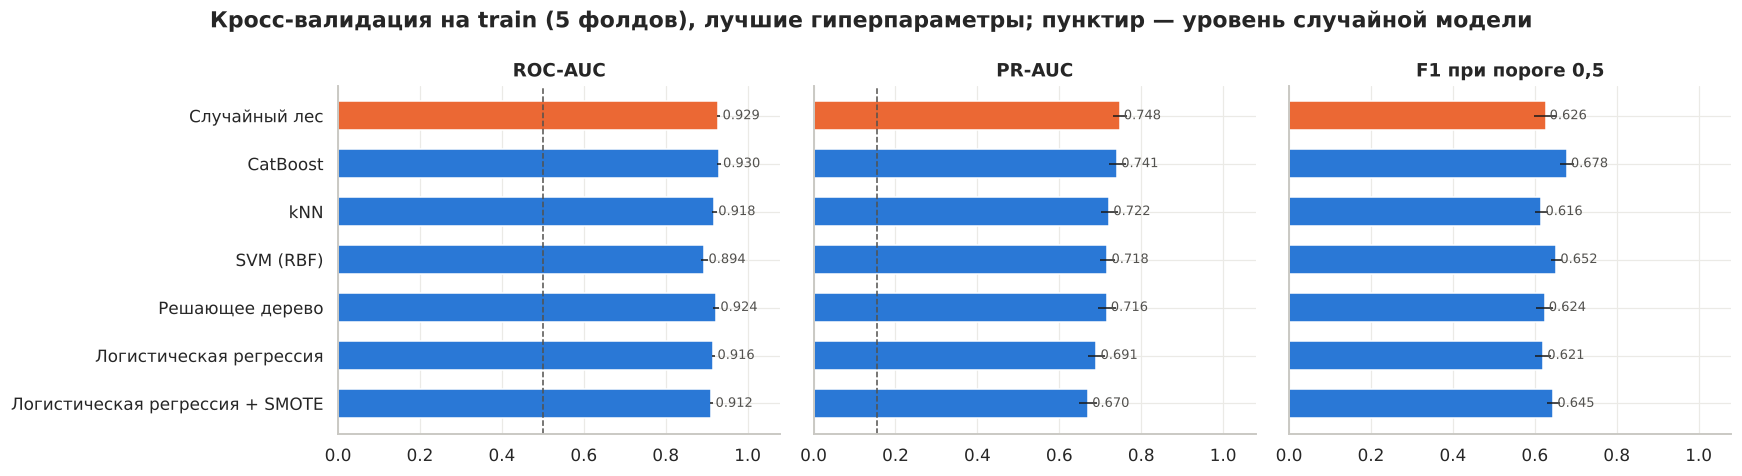

In [4]:
order = cv_table.drop(index="Dummy (самый частый класс)").sort_values("pr_auc").index
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for a, (m, title) in zip(axes, [("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("f1", "F1 при пороге 0,5")]):
    vals = cv_table.loc[order, m]
    errs = [searches[n].cv_results_[f"std_test_{m}"][searches[n].best_index_] for n in order]
    a.barh(order, vals, xerr=errs, color=[viz.ORANGE if n == order[-1] else viz.BLUE for n in order],
           height=0.6, error_kw={"elinewidth": 1})
    for y_, v in enumerate(vals):
        a.text(v + 0.01, y_, f"{v:.3f}", va="center", fontsize=8.5, color="#52514e")
    base = {"roc_auc": 0.5, "pr_auc": y_train.mean(), "f1": None}[m]
    if base:
        a.axvline(base, ls="--", lw=1, color="#52514e")
    a.set_title(title); a.set_xlim(0, 1.08)
plt.suptitle("Кросс-валидация на train (5 фолдов), лучшие гиперпараметры; пунктир — уровень случайной модели", fontweight="bold")
plt.tight_layout(); plt.show()

Все модели существенно лучше случайной (пунктир): ROC-AUC 0,89–0,93 против 0,5, PR-AUC 0,67–0,75 против 0,155. Разрыв между лучшими моделями и логистической регрессией (≈ 0,05–0,06 по PR-AUC) больше разброса по фолдам — нелинейные модели здесь действительно точнее.

### 2.1. Как гиперпараметры влияют на качество
Две иллюстрации из лекции: число соседей в kNN и глубина решающего дерева.

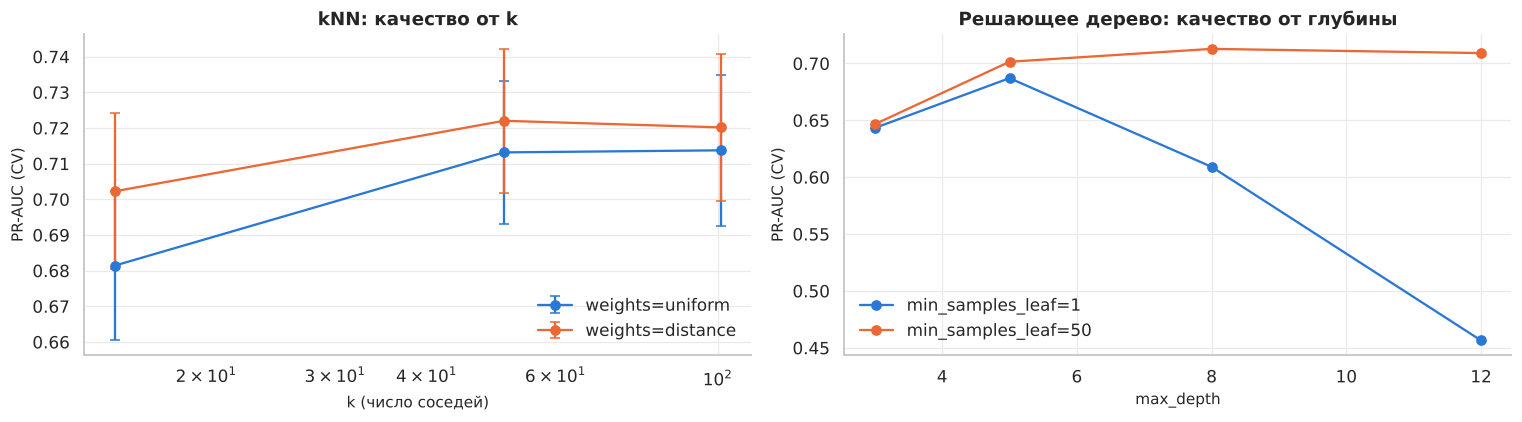

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
r = pd.DataFrame(searches["kNN"].cv_results_)
for w, c in zip(["uniform", "distance"], [viz.BLUE, viz.ORANGE]):
    part = r[r["param_clf__weights"] == w].sort_values("param_clf__n_neighbors")
    axes[0].errorbar(part["param_clf__n_neighbors"], part["mean_test_pr_auc"], yerr=part["std_test_pr_auc"],
                     marker="o", color=c, label=f"weights={w}", capsize=3)
axes[0].set_xscale("log"); axes[0].set_xlabel("k (число соседей)"); axes[0].set_ylabel("PR-AUC (CV)")
axes[0].set_title("kNN: качество от k"); axes[0].legend()
r = pd.DataFrame(searches["Решающее дерево"].cv_results_)
r = r[r["param_clf__class_weight"].isna()] if r["param_clf__class_weight"].isna().any() else r[r["param_clf__class_weight"].astype(str) == "None"]
for leaf, c in zip([1, 50], viz.CATEGORICAL[:2]):
    part = r[r["param_clf__min_samples_leaf"] == leaf].sort_values("param_clf__max_depth")
    axes[1].plot(part["param_clf__max_depth"], part["mean_test_pr_auc"], marker="o", color=c, label=f"min_samples_leaf={leaf}")
axes[1].set_xlabel("max_depth"); axes[1].set_ylabel("PR-AUC (CV)"); axes[1].set_title("Решающее дерево: качество от глубины")
axes[1].legend()
plt.tight_layout(); plt.show()

* **kNN:** при k = 15 качество заметно ниже (0,68–0,70), при k = 51 и 101 — около 0,71–0,72; взвешивание соседей по расстоянию (`distance`) лучше простого голосования при любом k. Малое k — сильная зависимость от шума отдельных соседей, большое — сглаживание.
* **Решающее дерево:** без ограничения на размер листа (`min_samples_leaf=1`) качество растёт до глубины 5, а дальше резко падает (до 0,46 при глубине 12) — классическое переобучение. С `min_samples_leaf=50` дерево остаётся устойчивым (≈ 0,70–0,71) при любой глубине: ограничение размера листа работает как регуляризация.

### 2.2. Веса классов и SMOTE: что они дают
Для каждой модели, где в сетке был параметр балансировки, сравниваю две конфигурации — с весами и без — при остальных лучших гиперпараметрах. **Brier score** — средний квадрат ошибки вероятности (меньше — лучше); он показывает, насколько предсказанные вероятности похожи на реальные частоты.

In [6]:
def as_text(v):
    # None в cv_results_ превращается в NaN — приводим обе формы к одному виду
    return "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v)

rows = []
for name, param in [("Логистическая регрессия", "clf__class_weight"), ("Решающее дерево", "clf__class_weight"),
                    ("Случайный лес", "clf__class_weight"), ("CatBoost", "clf__scale_pos_weight")]:
    gs = searches[name]
    r = pd.DataFrame(gs.cv_results_)
    mask = np.ones(len(r), dtype=bool)
    for k, v in gs.best_params_.items():
        if k != param:
            mask &= r["param_" + k].map(as_text).values == as_text(v)
    for _, row in r[mask].iterrows():
        w = as_text(row["param_" + param])
        label = "без весов" if w in ("None", "1.0") else f"{param.split('__')[1]}={w}"
        rows.append({"модель": name, "балансировка": label, "PR-AUC": row["mean_test_pr_auc"], "ROC-AUC": row["mean_test_roc_auc"], "F1@0.5": row["mean_test_f1"],
                     "recall@0.5": row["mean_test_recall"], "Brier": -row["mean_test_brier"]})
for name in ["Логистическая регрессия + SMOTE"]:
    r = cv_table.loc[name]
    rows.append({"модель": "Логистическая регрессия", "балансировка": "SMOTE", "PR-AUC": r["pr_auc"], "ROC-AUC": r["roc_auc"],
                 "F1@0.5": r["f1"], "recall@0.5": r["recall"], "Brier": r["brier"]})
weights = pd.DataFrame(rows).set_index(["модель", "балансировка"])
weights.style.format(precision=3).background_gradient(subset=["Brier"], cmap=viz.SEQ)

**Что дают веса классов и SMOTE** (кросс-валидация, при остальных лучших гиперпараметрах):

| Модель | PR-AUC без весов → с весами | recall@0,5 | Brier |
|---|---|---|---|
| логистическая регрессия | 0,691 → 0,671 (SMOTE: 0,670) | 0,55 → 0,80 (SMOTE: 0,63) | 0,075 → 0,108 (SMOTE: 0,079) |
| решающее дерево | 0,713 → 0,716 | 0,60 → 0,85 | 0,073 → 0,111 |
| случайный лес | 0,748 → 0,741 | 0,53 → 0,67 | 0,071 → 0,073 |
| CatBoost | 0,741 → 0,741 | 0,59 → 0,79 | 0,070 → 0,087 |

* **Качество ранжирования почти не меняется**: PR-AUC и ROC-AUC с весами и без отличаются не больше чем на 0,02 (у логистической регрессии веса и SMOTE даже немного ухудшают PR-AUC).
* **Сильно растёт recall при пороге 0,5** — но это не «модель стала лучше», а сдвиг всех вероятностей вверх: тот же эффект даёт снижение порога.
* **Вероятности становятся хуже откалиброваны**: Brier score растёт (у CatBoost 0,070 → 0,087, у дерева 0,073 → 0,111).

Вывод для выбора финальной модели: балансировку классов разумнее делать **порогом**, а не весами — так сохраняются честные вероятности. Лучшие значения ROC-AUC (0,932) и Brier (0,070) среди всех конфигураций — у CatBoost **без весов**, а по PR-AUC он равен варианту с весами (0,741).

### 2.3. Как выглядит решающее дерево небольшой глубины
Дерево глубины 3 — самая «прозрачная» модель: его правила можно прочитать целиком.

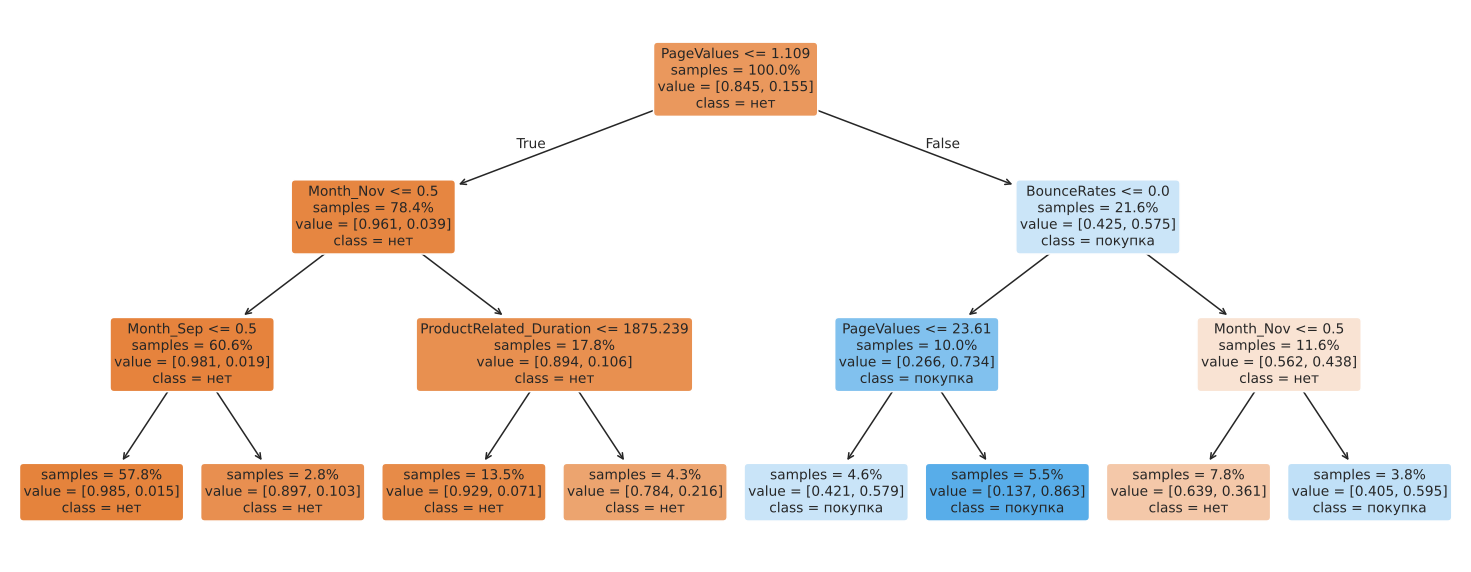

ROC-AUC этого дерева на test: 0.901


In [7]:
Xtr_t, Xte_t, pre_t = encode_for_trees(X_train, X_test)
small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE).fit(Xtr_t, y_train)
fig, ax = plt.subplots(figsize=(17, 6.5))
plot_tree(small_tree, feature_names=list(Xtr_t.columns), class_names=["нет", "покупка"], filled=True,
          impurity=False, proportion=True, rounded=True, fontsize=9, ax=ax)
plt.show()
print("ROC-AUC этого дерева на test:", round(roc_auc_score(y_test, small_tree.predict_proba(Xte_t)[:, 1]), 3))

**Как читать это дерево.** Первое разбиение — по `PageValues` ≤ 1,1: слева 78,4 % сессий с долей покупок 3,9 %, справа 21,6 % сессий с долей 57,5 %. Дальше слева дерево делит по месяцу (`Month_Nov`, `Month_Sep`) и длительности товарных страниц, справа — по `BounceRates` и снова по `PageValues`. Самый «покупательский» лист — `PageValues` > 23,6 и `BounceRates` = 0: 5,5 % сессий, 86,3 % из них с покупкой. Даже такое маленькое дерево даёт ROC-AUC 0,901 на тесте — и показывает, что модели «держатся» в первую очередь за `PageValues`.

## 3. Оценка на отложенной тестовой выборке
Все лучшие конфигурации переобучены на всём train (это делает `GridSearchCV`); test они видят впервые.

In [8]:
def scores_of(est, X):
    if hasattr(est, "predict_proba"):
        return est.predict_proba(X)[:, 1]
    return est.decision_function(X)

test_rows, test_scores = [], {}
for name, gs in searches.items():
    s = scores_of(gs.best_estimator_, X_test)
    pred = gs.best_estimator_.predict(X_test)
    test_scores[name] = s
    test_rows.append({"модель": name, "ROC-AUC": roc_auc_score(y_test, s), "PR-AUC": average_precision_score(y_test, s),
                      "F1@0.5": f1_score(y_test, pred), "precision@0.5": precision_score(y_test, pred, zero_division=0),
                      "recall@0.5": recall_score(y_test, pred), "accuracy@0.5": accuracy_score(y_test, pred),
                      "PR-AUC на CV": cv_table.loc[name, "pr_auc"]})
test_table = pd.DataFrame(test_rows).set_index("модель").sort_values("PR-AUC", ascending=False)
test_table.style.format(precision=3).background_gradient(subset=["ROC-AUC", "PR-AUC", "F1@0.5"], cmap=viz.SEQ)

,ROC-AUC,PR-AUC,F1@0.5,precision@0.5,recall@0.5,accuracy@0.5,PR-AUC на CV
модель,,,,,,,
CatBoost,0.928,0.745,0.651,0.561,0.775,0.871,0.741
Случайный лес,0.918,0.728,0.594,0.754,0.490,0.896,0.748
SVM (RBF),0.901,0.705,0.617,0.702,0.550,0.894,0.718
Решающее дерево,0.922,0.699,0.629,0.503,0.838,0.847,0.716
kNN,0.904,0.689,0.582,0.691,0.503,0.888,0.722
Логистическая регрессия,0.912,0.667,0.617,0.712,0.545,0.895,0.691
Логистическая регрессия + SMOTE,0.908,0.648,0.629,0.654,0.605,0.889,0.670
Dummy (самый частый класс),0.500,0.155,0.000,0.000,0.000,0.845,0.155


**Тестовая выборка** (2 466 сессий, 382 покупки). Порядок моделей в целом совпадает с кросс-валидацией, а значения близки к CV — признаков переобучения на подборе гиперпараметров нет:
* CatBoost: ROC-AUC 0,928, PR-AUC 0,745 (на CV 0,741);
* случайный лес: 0,918 и 0,728 (на CV 0,748 — на тесте он немного уступил);
* SVM 0,705, решающее дерево 0,699, kNN 0,689, логистическая регрессия 0,667 по PR-AUC.

Тестовая выборка используется только для оценки; выбор финальной модели сделан по кросс-валидации (раздел 4).

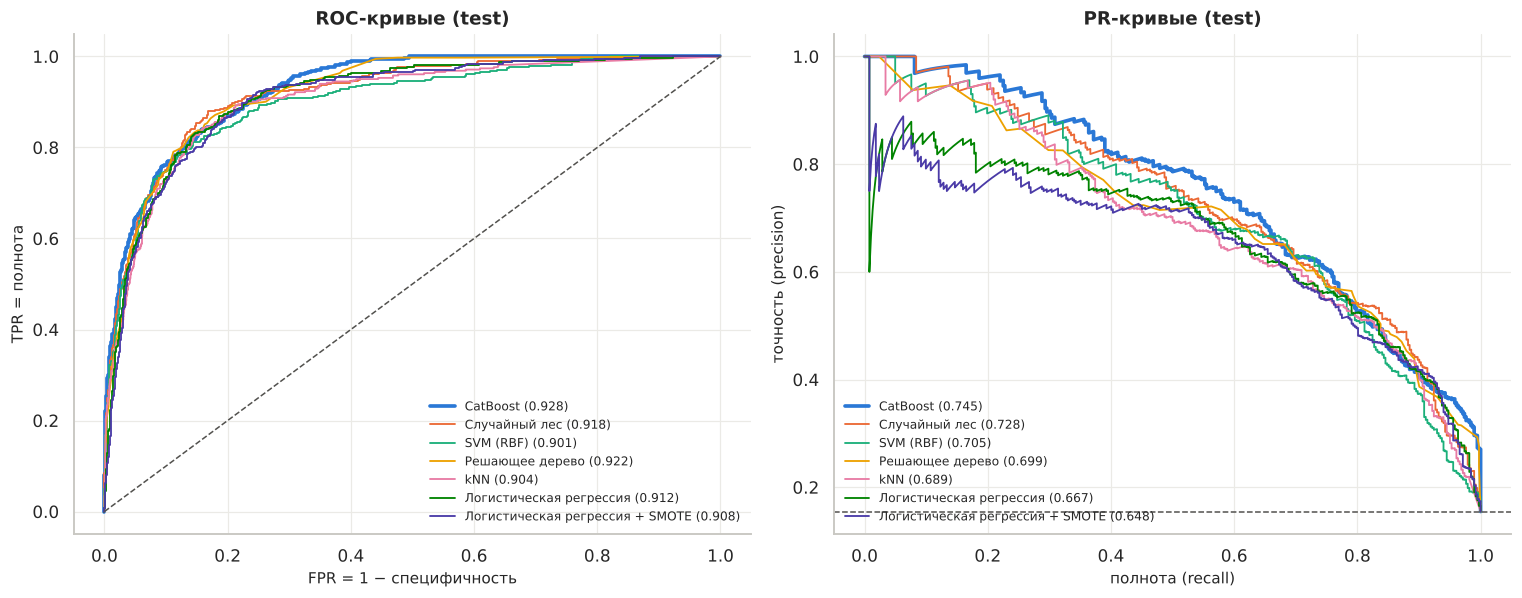

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
names = [n for n in test_table.index if not n.startswith("Dummy")]
for i, n in enumerate(names):
    s = test_scores[n]
    fpr, tpr, _ = roc_curve(y_test, s)
    pr, rc, _ = precision_recall_curve(y_test, s)
    lw = 2.4 if i == 0 else 1.2
    axes[0].plot(fpr, tpr, lw=lw, color=viz.CATEGORICAL[i % 8], label=f"{n} ({roc_auc_score(y_test, s):.3f})")
    axes[1].plot(rc, pr, lw=lw, color=viz.CATEGORICAL[i % 8], label=f"{n} ({average_precision_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="#52514e", lw=1)
axes[0].set_xlabel("FPR = 1 − специфичность"); axes[0].set_ylabel("TPR = полнота"); axes[0].set_title("ROC-кривые (test)")
axes[1].axhline(y_test.mean(), ls="--", color="#52514e", lw=1)
axes[1].set_xlabel("полнота (recall)"); axes[1].set_ylabel("точность (precision)"); axes[1].set_title("PR-кривые (test)")
for a in axes:
    a.legend(fontsize=8, loc="lower left" if a is axes[1] else "lower right")
plt.tight_layout(); plt.show()

ROC-кривые всех моделей почти сливаются в области малых FPR — по ранжированию модели близки. PR-кривые различаются заметнее: при полноте до 0,5 CatBoost и случайный лес удерживают точность 0,8–0,95, а логистическая регрессия и вариант со SMOTE — около 0,72–0,85. Справа все кривые сходятся: найти почти все покупки можно только ценой точности ~0,2–0,3.

## 4. Финальная модель и выбор порога
Финальная модель и её параметры зафиксированы в `src/model.py` (функция `make_final_model`) — тот же код использует дашборд (lab6), поэтому прогнозы в дашборде совпадают с моделью из этой работы.

Порог 0,5 не обязан быть лучшим при дисбалансе классов. Порог выбираю **только по train**: беру out-of-fold вероятности (каждая сессия train получает прогноз модели, которая её не видела) и нахожу порог, максимизирующий F1. Затем применяю этот порог к test.

In [10]:
print("Параметры финальной модели:", FINAL_PARAMS)
final = Pipeline([("pre", make_preprocessor("tree")), ("clf", make_final_model())])
oof = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
thr, f1_oof = choose_threshold(y_train, oof)
print(f"Порог по максимуму F1 на out-of-fold прогнозах train: {thr:.2f} (F1 = {f1_oof:.3f})")

final.fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
pred_05, pred_thr = (p_test >= 0.5).astype(int), (p_test >= thr).astype(int)
summary = pd.DataFrame({
    "порог 0,5": [precision_score(y_test, pred_05), recall_score(y_test, pred_05), f1_score(y_test, pred_05),
                  balanced_accuracy_score(y_test, pred_05), accuracy_score(y_test, pred_05)],
    f"порог {thr:.2f}": [precision_score(y_test, pred_thr), recall_score(y_test, pred_thr), f1_score(y_test, pred_thr),
                         balanced_accuracy_score(y_test, pred_thr), accuracy_score(y_test, pred_thr)],
}, index=["precision", "recall", "F1", "balanced accuracy", "accuracy"])
print(f"Test: ROC-AUC = {roc_auc_score(y_test, p_test):.3f}, PR-AUC = {average_precision_score(y_test, p_test):.3f}")
summary.round(3)

Параметры финальной модели: {'iterations': 500, 'learning_rate': 0.05, 'depth': 6, 'scale_pos_weight': 1.0}


Порог по максимуму F1 на out-of-fold прогнозах train: 0.27 (F1 = 0.683)


Test: ROC-AUC = 0.929, PR-AUC = 0.744


,"порог 0,5",порог 0.27
precision,0.711,0.614
recall,0.565,0.749
F1,0.630,0.675
balanced accuracy,0.762,0.831
accuracy,0.897,0.888


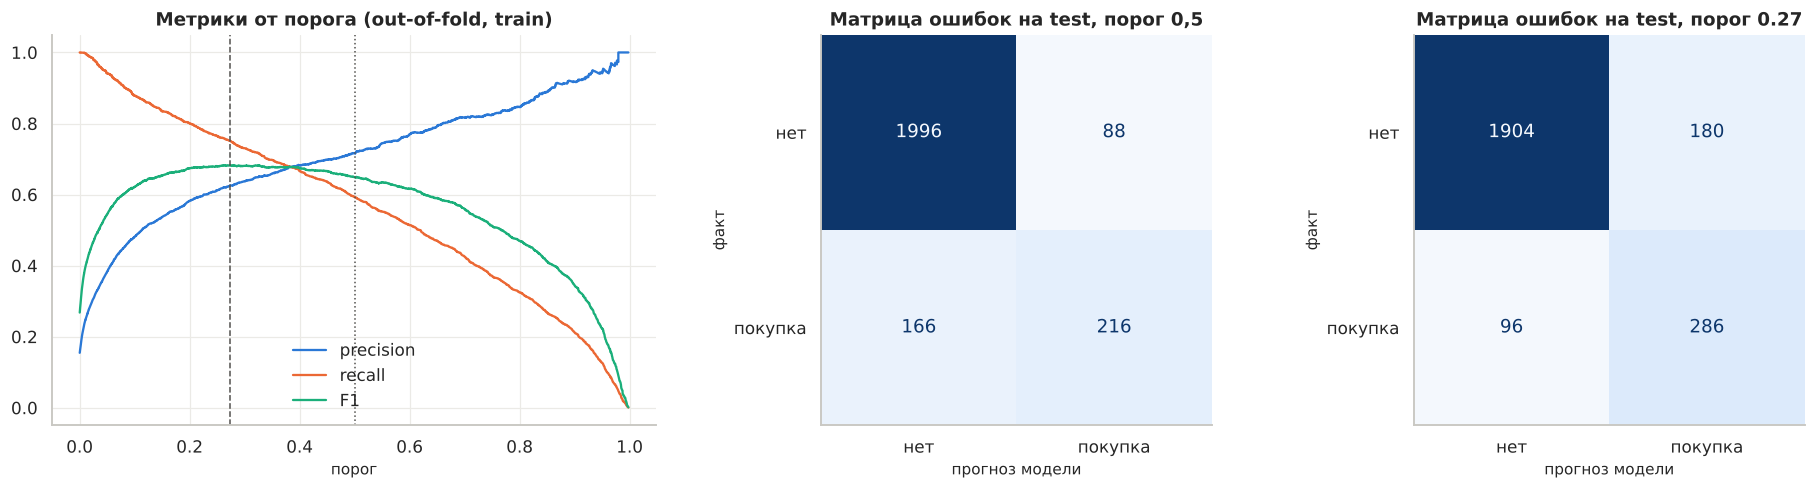

При пороге 0.27: найдено 286 из 382 покупок; из 466 сессий, отмеченных как «покупка», верно 286; ложных срабатываний 180 из 2084 сессий без покупки


In [11]:
pr, rc, th = precision_recall_curve(y_train, oof)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
axes[0].plot(th, pr[:-1], color=viz.BLUE, label="precision")
axes[0].plot(th, rc[:-1], color=viz.ORANGE, label="recall")
f1c = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
axes[0].plot(th, f1c, color=viz.CATEGORICAL[2], label="F1")
axes[0].axvline(thr, ls="--", color="#52514e", lw=1); axes[0].axvline(0.5, ls=":", color="#52514e", lw=1)
axes[0].set_xlabel("порог"); axes[0].set_title("Метрики от порога (out-of-fold, train)"); axes[0].legend()
for a, pred, t in [(axes[1], pred_05, "порог 0,5"), (axes[2], pred_thr, f"порог {thr:.2f}")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["нет", "покупка"]).plot(
        ax=a, cmap=viz.SEQ, colorbar=False, values_format="d")
    a.set_title(f"Матрица ошибок на test, {t}"); a.grid(False)
    a.set_xlabel("прогноз модели"); a.set_ylabel("факт")
plt.tight_layout(); plt.show()
cm = confusion_matrix(y_test, pred_thr)
tn, fp, fn, tp = cm.ravel()
print(f"При пороге {thr:.2f}: найдено {tp} из {tp + fn} покупок; из {tp + fp} сессий, отмеченных как «покупка», "
      f"верно {tp}; ложных срабатываний {fp} из {tn + fp} сессий без покупки")

**Выбор финальной модели (по кросс-валидации, не по тесту).** Лидеры по PR-AUC на CV — случайный лес и CatBoost — неразличимы с учётом разброса по фолдам. Выбираю **CatBoost**: у него лучший ROC-AUC на CV, лучшие F1 и balanced accuracy, и именно его использовали на практике по развёртыванию. В финальной модели не использую веса классов (`scale_pos_weight = 1`): как видно в п. 2.2, веса почти не меняют качество ранжирования, но искажают шкалу вероятностей, а дашборд показывает именно вероятности (вкладки «Отдельные прогнозы» и «Что если»). Дисбаланс классов учитываю порогом. На out-of-fold прогнозах финальная модель даёт ROC-AUC 0,932 и PR-AUC 0,740 (раздел 8) — на уровне лучших конфигураций.

**Порог.** Максимум F1 на out-of-fold прогнозах достигается при пороге 0,27 (F1 = 0,683). На графике слева видно, что кривая F1 почти плоская в диапазоне 0,2–0,45, так что точное значение порога не критично.

**На тесте** (2 466 сессий, 382 покупки):
* при пороге 0,5: precision 0,711, recall 0,565, F1 0,630 — модель находит 216 покупок из 382, ошибочно отмечает 88 сессий;
* при пороге 0,27: precision 0,614, recall 0,749, F1 0,675 — находит 286 покупок из 382, ложных срабатываний 180 из 2 084 сессий без покупки.

Снижение порога «покупает» 70 найденных покупок ценой 92 дополнительных ложных срабатываний; balanced accuracy растёт с 0,762 до 0,831, а accuracy почти не меняется (0,897 → 0,888) — ещё один пример того, что accuracy здесь малоинформативна.

In [12]:
# Сохраняю результаты: их показывает дашборд (lab6) и использует итоговый проект
import json
from pathlib import Path
res_dir = Path("..") / "results"; res_dir.mkdir(exist_ok=True)
cv_table.drop(columns=["время, с"]).reset_index().to_csv(res_dir / "model_comparison_cv.csv", index=False)
test_table.reset_index().to_csv(res_dir / "model_comparison_test.csv", index=False)
final_metrics = {
    "model": "CatBoost", "params": FINAL_PARAMS,
    "params_short": f"depth={FINAL_PARAMS['depth']}, {FINAL_PARAMS['iterations']} деревьев",
    "threshold": round(thr, 4), "oof_f1_at_threshold": round(f1_oof, 4),
    "test_roc_auc": roc_auc_score(y_test, p_test), "test_pr_auc": average_precision_score(y_test, p_test),
    "test_f1_at_threshold": f1_score(y_test, pred_thr), "test_precision_at_threshold": precision_score(y_test, pred_thr),
    "test_recall_at_threshold": recall_score(y_test, pred_thr), "test_f1_at_05": f1_score(y_test, pred_05),
    "confusion_matrix_at_threshold": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
}
(res_dir / "final_metrics.json").write_text(json.dumps(final_metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(final_metrics, ensure_ascii=False, indent=2))

{
  "model": "CatBoost",
  "params": {
    "iterations": 500,
    "learning_rate": 0.05,
    "depth": 6,
    "scale_pos_weight": 1.0
  },
  "params_short": "depth=6, 500 деревьев",
  "threshold": 0.2738,
  "oof_f1_at_threshold": 0.6831,
  "test_roc_auc": 0.9292854558792495,
  "test_pr_auc": 0.7439995803320434,
  "test_f1_at_threshold": 0.6745283018867925,
  "test_precision_at_threshold": 0.6137339055793991,
  "test_recall_at_threshold": 0.7486910994764397,
  "test_f1_at_05": 0.6297376093294461,
  "confusion_matrix_at_threshold": {
    "tn": 1904,
    "fp": 180,
    "fn": 96,
    "tp": 286
  }
}


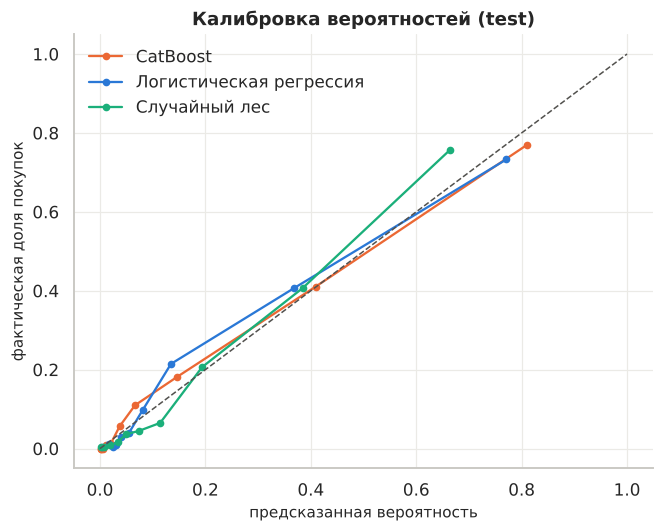

In [13]:
fig, ax = plt.subplots(figsize=(6.2, 5))
for n, c in [("CatBoost", viz.ORANGE), ("Логистическая регрессия", viz.BLUE), ("Случайный лес", viz.CATEGORICAL[2])]:
    s = p_test if n == "CatBoost" else test_scores[n]
    fr, mp = calibration_curve(y_test, s, n_bins=10, strategy="quantile")
    ax.plot(mp, fr, "o-", color=c, label=n, ms=4)
ax.plot([0, 1], [0, 1], ls="--", color="#52514e", lw=1)
ax.set_xlabel("предсказанная вероятность"); ax.set_ylabel("фактическая доля покупок")
ax.set_title("Калибровка вероятностей (test)"); ax.legend()
plt.tight_layout(); plt.show()

**Калибровка.** У CatBoost (без весов классов) точки лежат близко к диагонали: если модель говорит «вероятность покупки 0,4», то покупкой действительно заканчиваются около 40 % таких сессий. Случайный лес занижает высокие вероятности (предсказывает ~0,66 там, где фактическая доля ~0,76), логистическая регрессия немного занижает вероятности в диапазоне 0,1–0,4. Для дашборда, где пользователь видит вероятность конкретной сессии, хорошая калибровка важна — это ещё один довод за выбранную модель.

## 5. Интерпретация качества словами

**Хорошая ли получилась модель?**

* **Ранжирование — хорошее.** ROC-AUC 0,929 означает: если взять случайную сессию с покупкой и случайную без, модель в 93 случаях из 100 поставит первую выше. PR-AUC 0,744 почти в 5 раз выше уровня случайной модели (0,155).
* **В терминах магазина** (порог 0,27): из сессий, которые модель отметила как «покупка», покупкой заканчиваются 61 % — в 4 раза чаще, чем в среднем по сайту (15,5 %); при этом модель находит 3 из 4 покупок (75 %). Если цель — показывать персональное предложение или звать консультанта только «перспективным» посетителям, это хороший результат: усилия тратятся на ~19 % сессий (466 из 2 466), где сосредоточены 75 % покупок.
* **Чего модель не умеет.** Четверть покупок (96 из 382) она пропускает, и почти все такие сессии выглядят как обычные «непокупки» (нулевой `PageValues`, см. разбор FN в разделе 7). Как инструмент «точно предсказать каждую покупку» модель недостаточна.
* **Насколько можно доверять оценке.** Значения на тесте совпадают с кросс-валидацией (PR-AUC 0,744 против 0,740 на out-of-fold), разброс по фолдам ±0,02 — оценка устойчива. Главная оговорка — сильная зависимость от одного признака `PageValues` (раздел 8).

## 6. Интерпретация модели в целом
### 6.1. Логистическая регрессия: коэффициенты
Признаки стандартизованы, поэтому коэффициенты сопоставимы между собой: $e^{\beta}$ — во сколько раз меняются шансы покупки при росте признака на одно стандартное отклонение (для one-hot — при переходе в эту категорию). Из-за мультиколлинеарности (lab4) коэффициенты сильно согласованных признаков нужно читать вместе.

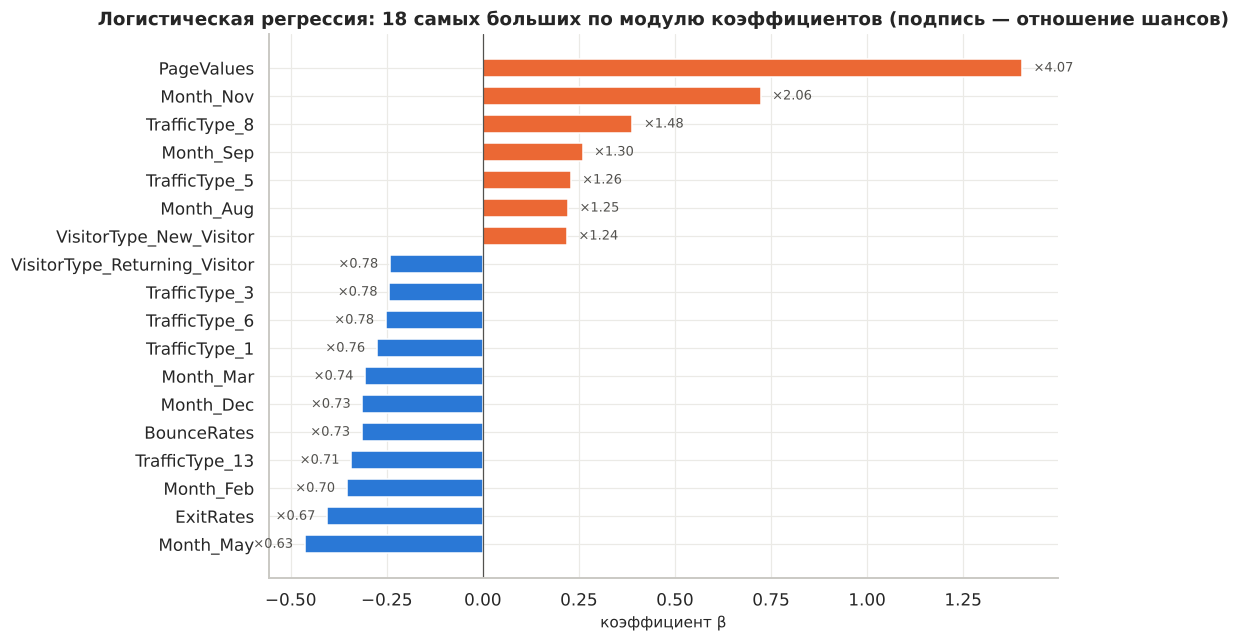

In [14]:
lr = searches["Логистическая регрессия"].best_estimator_
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=pretty_names(lr.named_steps["pre"].get_feature_names_out()))
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:18]).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index, top.values, color=[viz.ORANGE if v > 0 else viz.BLUE for v in top.values], height=0.65)
ax.axvline(0, color="#52514e", lw=0.8)
for i, v in enumerate(top.values):
    ax.text(v + (0.03 if v > 0 else -0.03), i, f"×{np.exp(v):.2f}", va="center", ha="left" if v > 0 else "right",
            fontsize=8.5, color="#52514e")
ax.set_title("Логистическая регрессия: 18 самых больших по модулю коэффициентов (подпись — отношение шансов)")
ax.set_xlabel("коэффициент β")
plt.tight_layout(); plt.show()

**Что видно по коэффициентам логистической регрессии** (признаки стандартизованы, числовые — после `log1p`):
* самый большой коэффициент у `PageValues`: рост `log1p(PageValues)` на одно стандартное отклонение увеличивает шансы покупки в 4,07 раза;
* среди месяцев шансы выше в ноябре (×2,06), сентябре (×1,30) и августе (×1,25) и ниже в мае (×0,63), феврале (×0,70), декабре (×0,73) и марте (×0,74) — относительно «среднего» месяца;
* `ExitRates` (×0,67) и `BounceRates` (×0,73) уменьшают шансы;
* у источников трафика разные знаки: код 8 (×1,48) и 5 (×1,26) — выше, коды 13, 1, 6, 3 — ниже;
* новые посетители — ×1,24, вернувшиеся — ×0,78.

Направления совпадают с тем, что было видно в EDA, но теперь это не описание, а вклад признака **при прочих равных** в линейной модели. Из-за мультиколлинеарности (`BounceRates`–`ExitRates`, счётчики–длительности) величины отдельных коэффициентов таких пар не стоит интерпретировать по отдельности.

### 6.2. Важность признаков финальной модели: перестановочная важность
Перестановочная важность (permutation importance) на **test**: насколько падает PR-AUC, если случайно перемешать значения одного признака (связь признака с ответом разрушается). Для номинальных признаков перемешивается исходный столбец целиком, поэтому важность считается для признака, а не для отдельного one-hot столбца.

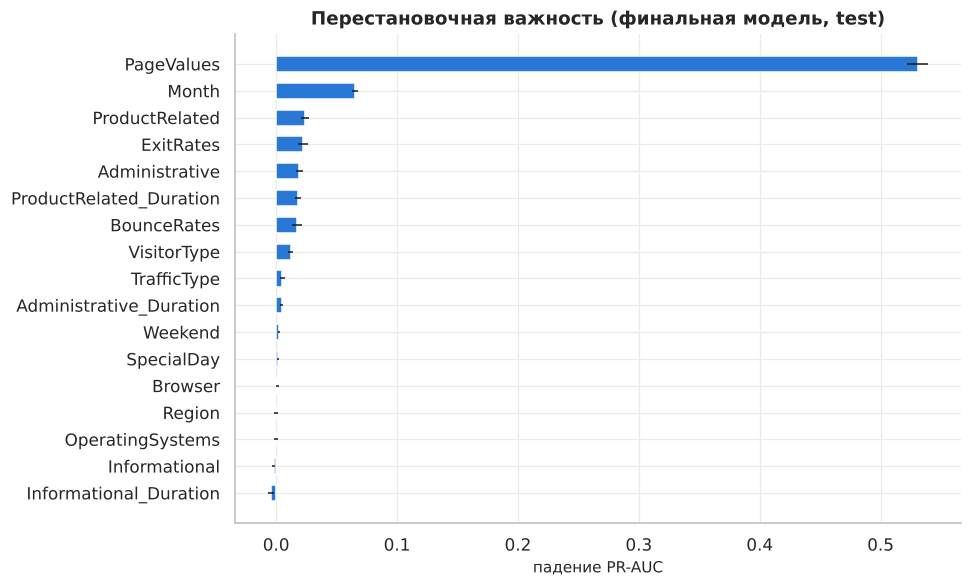

,PageValues,Month,ProductRelated,ExitRates,Administrative,ProductRelated_Duration,BounceRates,VisitorType
среднее падение PR-AUC,0.5306,0.0652,0.0237,0.0221,0.0191,0.0181,0.0172,0.0119
σ,0.0089,0.0026,0.0031,0.0040,0.0028,0.0025,0.0041,0.0023


In [15]:
perm = permutation_importance(final, X_test, y_test, scoring="average_precision", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=1)
pi = pd.DataFrame({"среднее падение PR-AUC": perm.importances_mean, "σ": perm.importances_std},
                  index=X_test.columns).sort_values("среднее падение PR-AUC")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(pi.index, pi["среднее падение PR-AUC"], xerr=pi["σ"], color=viz.BLUE, height=0.6, error_kw={"elinewidth": 1})
ax.set_title("Перестановочная важность (финальная модель, test)"); ax.set_xlabel("падение PR-AUC")
plt.tight_layout(); plt.show()
pi.sort_values("среднее падение PR-AUC", ascending=False).head(8).round(4).T

**Перестановочная важность финальной модели.** Если перемешать `PageValues`, PR-AUC падает на 0,53 — то есть почти до уровня случайной модели (0,744 − 0,53 ≈ 0,21). Следующие по важности — `Month` (−0,065), `ProductRelated` (−0,024), `ExitRates` (−0,022), `Administrative` (−0,019), `ProductRelated_Duration` (−0,018), `BounceRates` (−0,017). Остальные признаки по отдельности почти ничего не дают — часто потому, что их информацию дублируют согласованные с ними признаки (перемешивание одного из пары не мешает модели взять информацию из второго).

### 6.3. SHAP-значения
SHAP раскладывает прогноз модели (в логитах) для каждой сессии на сумму вкладов признаков: $f(x) = \text{base} + \sum_j \varphi_j(x)$. Положительный вклад сдвигает прогноз к «покупке», отрицательный — от неё. Для one-hot признаков вклады столбцов одного исходного признака складываются (например, все `Month_*` → `Month`).

Базовое значение (логит): -3.331 → вероятность 0.035


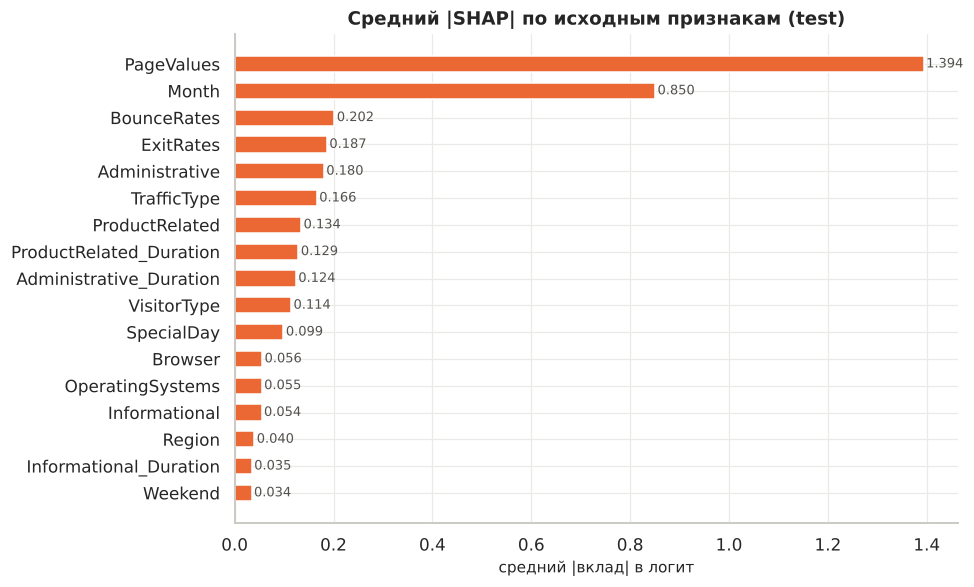

In [16]:
clf = final.named_steps["clf"]
Xte_raw = final.named_steps["pre"].transform(X_test)          # имена столбцов — как при обучении модели
explainer = shap.TreeExplainer(clf)
sv = explainer(Xte_raw)
Xte_enc = Xte_raw.copy(); Xte_enc.columns = pretty_names(Xte_raw.columns)   # «…_infrequent_sklearn» -> «…_other»
sv.feature_names = list(Xte_enc.columns)
print("Базовое значение (логит):", round(float(np.ravel(sv.base_values)[0]), 3),
      "→ вероятность", round(1 / (1 + np.exp(-float(np.ravel(sv.base_values)[0]))), 3))

# сгруппировать one-hot столбцы по исходному признаку
groups = {}
for c in Xte_enc.columns:
    base = next((f for f in NOMINAL if c.startswith(f + "_")), c)
    groups.setdefault(base, []).append(c)
sv_grouped = pd.DataFrame({g: sv.values[:, [Xte_enc.columns.get_loc(c) for c in cols]].sum(axis=1) for g, cols in groups.items()})
mean_abs = sv_grouped.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(mean_abs.index, mean_abs.values, color=viz.ORANGE, height=0.6)
for i, v in enumerate(mean_abs.values):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8.5, color="#52514e")
ax.set_title("Средний |SHAP| по исходным признакам (test)"); ax.set_xlabel("средний |вклад| в логит")
plt.tight_layout(); plt.show()

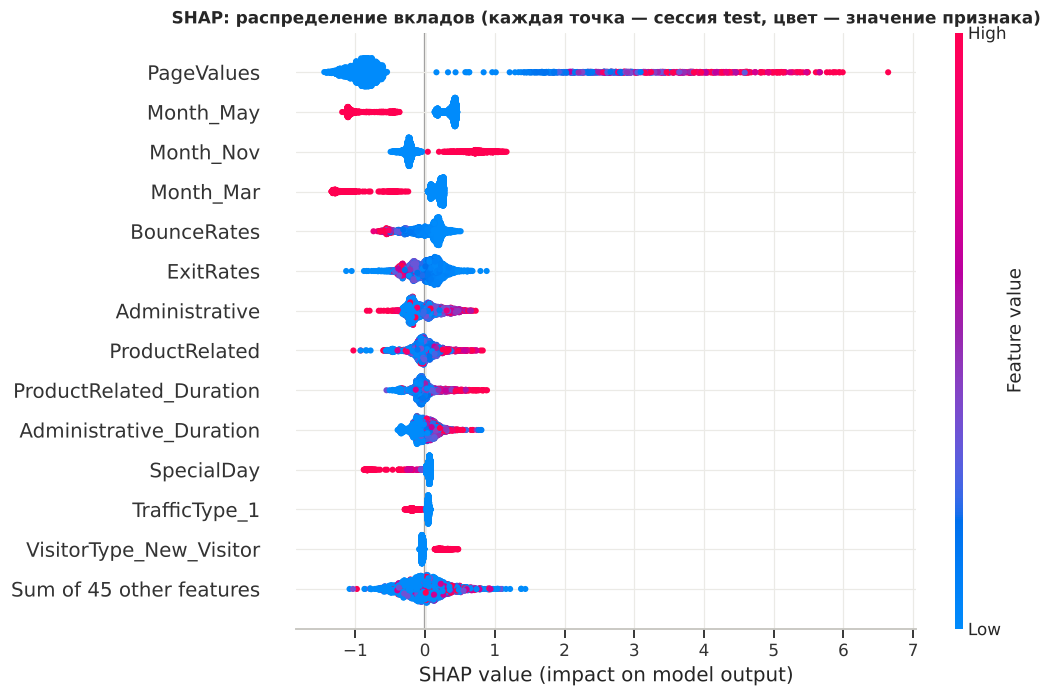

In [17]:
plt.figure()
shap.plots.beeswarm(sv, max_display=14, show=False, plot_size=(10, 6.5))
plt.title("SHAP: распределение вкладов (каждая точка — сессия test, цвет — значение признака)", fontsize=11)
plt.tight_layout(); plt.show()

**SHAP: глобальная картина.**
* Средний |SHAP| у `PageValues` — 1,39 логита, у `Month` — 0,85; дальше `BounceRates`, `ExitRates`, `Administrative`, `TrafficType` (0,17–0,20). `Region`, `Weekend`, `Informational(_Duration)` вносят меньше 0,06.
* На «пчелином рое»: нулевой `PageValues` (синие точки) у всех сессий сдвигает прогноз примерно на −1 логит, а любое ненулевое значение — на +1…+6; это крупнейшие вклады во всей модели.
* Месяц работает через отдельные one-hot столбцы: сессия в мае или марте получает около −1 логита, в ноябре — около +1.
* Высокие `BounceRates` и `ExitRates` (красные точки) смещают прогноз влево, высокие `Administrative`, `ProductRelated`, `ProductRelated_Duration` — вправо; `SpecialDay` > 0 — влево.
* Базовое значение −3,33 логита — средний логит модели на тесте (из-за асимметрии распределения логитов он соответствует вероятности 0,035, а не средней доле покупок 0,155).

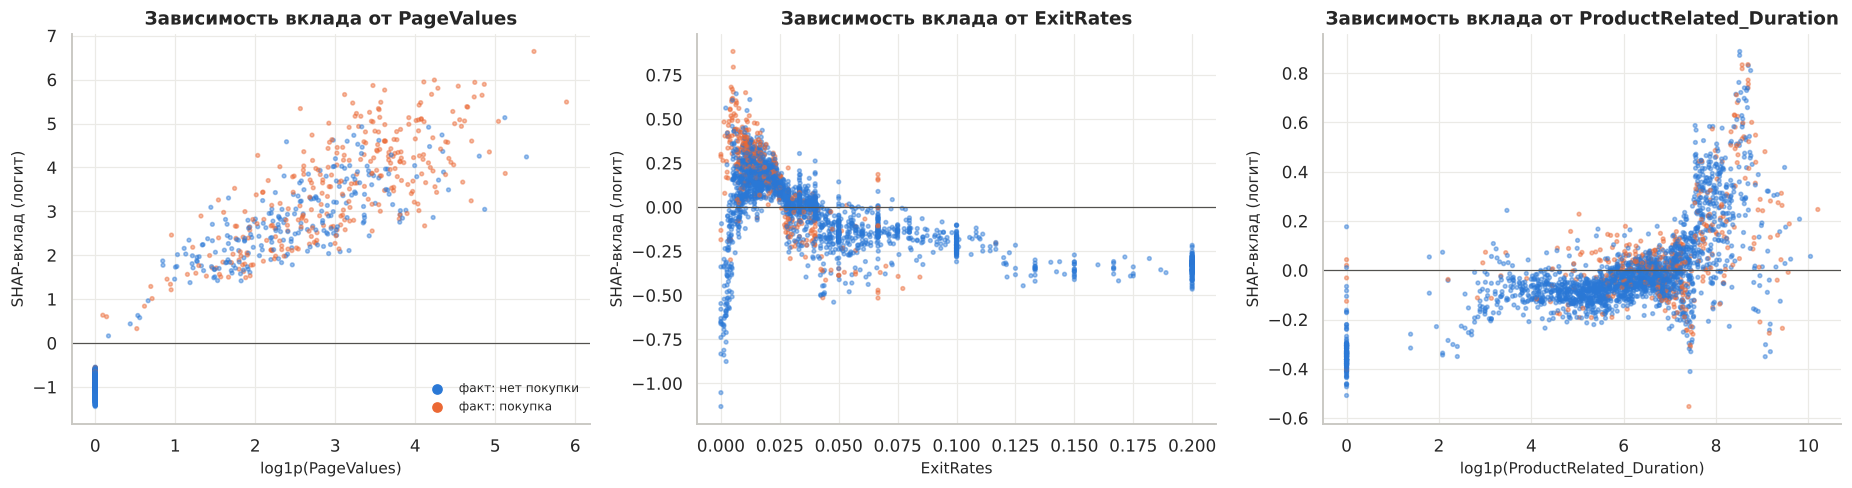

Средний суммарный SHAP-вклад Month по месяцам (test):


,Feb,Mar,May,June,Jul,Aug,Sep,Oct,Nov,Dec
вклад,0.297,-0.981,-0.971,0.254,0.358,0.401,0.618,0.339,1.29,0.216


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for a, c, logx in [(axes[0], "PageValues", True), (axes[1], "ExitRates", False), (axes[2], "ProductRelated_Duration", True)]:
    xv = Xte_enc[c].values
    j = Xte_enc.columns.get_loc(c)
    a.scatter(np.log1p(xv) if logx else xv, sv.values[:, j], s=6, alpha=0.45,
              c=[viz.CLASS_PALETTE[int(v)] for v in y_test.values])
    a.axhline(0, color="#52514e", lw=0.8)
    a.set_xlabel(f"log1p({c})" if logx else c); a.set_ylabel("SHAP-вклад (логит)")
    a.set_title(f"Зависимость вклада от {c}")
axes[0].scatter([], [], c=viz.CLASS_PALETTE[0], label="факт: нет покупки"); axes[0].scatter([], [], c=viz.CLASS_PALETTE[1], label="факт: покупка")
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
month_cols = [c for c in Xte_enc.columns if c.startswith("Month_")]
mshap = pd.Series({c.replace("Month_", ""): sv_grouped["Month"].values[(Xte_enc[c] == 1).values].mean() for c in month_cols})
print("Средний суммарный SHAP-вклад Month по месяцам (test):")
mshap.reindex(["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]).round(3).to_frame("вклад").T

**Как вклад зависит от значения признака:**
* `PageValues`: при нуле вклад ≈ −1 логит; уже небольшие положительные значения дают положительный вклад, который растёт почти линейно с `log1p(PageValues)` до +5…+6. Модель по сути научилась правилу «есть ли у сессии ценные страницы» и «насколько они ценны».
* `ExitRates`: до ≈ 0,025 вклад положительный (до +0,5), после — отрицательный и выходит на плато около −0,3 при больших значениях; у сессий с `ExitRates` ≈ 0 бывает и сильный отрицательный вклад — это короткие сессии, где метрика вырождена.
* `ProductRelated_Duration`: нулевое время — около −0,35; от ~1 до ~30 минут (`log1p` 4–7,5) вклад небольшой отрицательный, после ~30 минут растёт до +0,8.
* По месяцам средний суммарный вклад максимален в ноябре (+1,29) и минимален в марте и мае (≈ −0,98); в остальных месяцах — от +0,22 до +0,62.

## 7. Интерпретация отдельных прогнозов
Разберу три сессии из test: верно найденную покупку (TP), пропущенную покупку (FN) и ложное срабатывание (FP) при выбранном пороге. Водопадная диаграмма показывает, как от базового значения модель приходит к итоговому логиту.

,PageValues,ExitRates,BounceRates,ProductRelated,ProductRelated_Duration,Administrative,Month,VisitorType,TrafficType,вероятность
TP: уверенно найденная покупка,71.488,0.015385,0.0,12,755.0,0,May,New_Visitor,2,0.991
FN: пропущенная покупка,0.0,0.006944,0.008333,24,1433.163333,1,Aug,Returning_Visitor,4,0.011
FP: ложное срабатывание,166.373553,0.00625,0.0,15,443.566667,2,June,New_Visitor,5,0.949


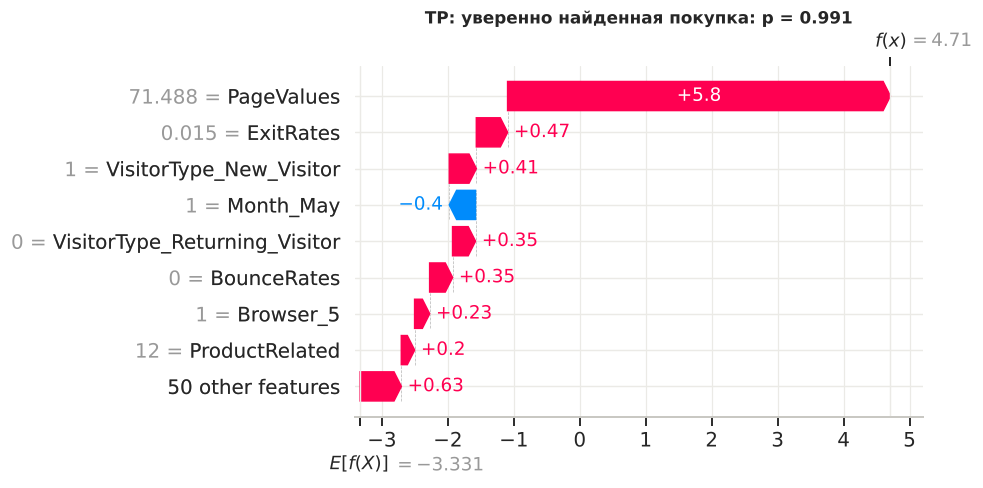

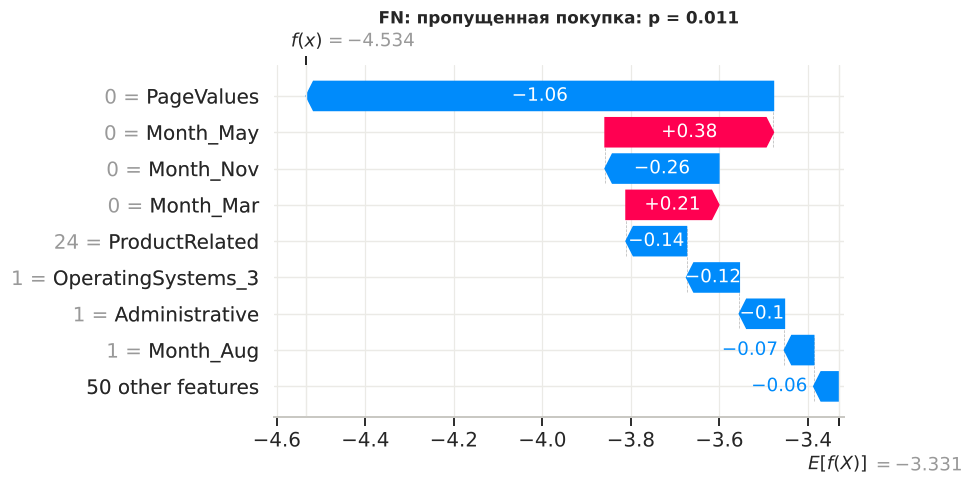

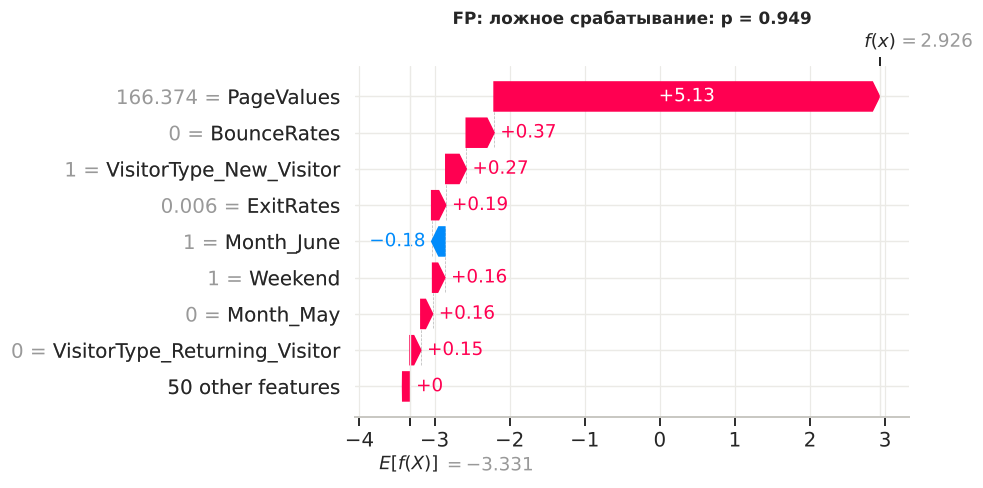

In [19]:
res = pd.DataFrame({"p": p_test, "y": y_test.values, "pred": pred_thr}, index=X_test.index)
pick = {
    "TP: уверенно найденная покупка": res[(res.y == 1) & (res.pred == 1)]["p"].idxmax(),
    "FN: пропущенная покупка": res[(res.y == 1) & (res.pred == 0)]["p"].idxmin(),
    "FP: ложное срабатывание": res[(res.y == 0) & (res.pred == 1)]["p"].idxmax(),
}
cols_show = ["PageValues", "ExitRates", "BounceRates", "ProductRelated", "ProductRelated_Duration",
             "Administrative", "Month", "VisitorType", "TrafficType"]
display(pd.DataFrame({k: X_test.loc[i, cols_show] for k, i in pick.items()}).T.assign(
    **{"вероятность": [round(res.loc[i, "p"], 3) for i in pick.values()]}))
for title, idx in pick.items():
    pos = X_test.index.get_loc(idx)
    plt.figure()
    shap.plots.waterfall(sv[pos], max_display=9, show=False)
    plt.title(f"{title}: p = {res.loc[idx, 'p']:.3f}", fontsize=11)
    plt.gcf().set_size_inches(9, 4.6)
    plt.tight_layout(); plt.show()

**Разбор отдельных прогнозов.**
* **TP (p = 0,991):** новый посетитель в мае, `PageValues` = 71,5. Один `PageValues` добавляет +5,8 логита — больше, чем всё остальное вместе; небольшой минус даёт май (−0,4), плюсы — низкий `ExitRates`, новый посетитель, нулевой `BounceRates`.
* **FN (p = 0,011), пропущенная покупка:** вернувшийся посетитель в августе, 24 товарные страницы, ~24 минуты на них, `PageValues` = 0. Нулевой `PageValues` даёт −1,06, и ни один другой признак не тянет прогноз вверх — по признакам эта сессия неотличима от типичной «непокупки». Такие ошибки модель исправить не может: в данных просто нет сигнала.
* **FP (p = 0,949), ложное срабатывание:** новый посетитель в июне, `PageValues` = 166,4 (очень высокий), низкие `ExitRates` и `BounceRates`. Всё, что модель знает о покупателях, у этой сессии есть, но покупки не случилось. Для бизнеса это «тёплый» посетитель — показать ему предложение как раз разумно.

## 8. Проверка: насколько модель зависит от `PageValues`
`PageValues` — метрика Google Analytics: средняя «ценность» просмотренных страниц, которая рассчитывается по доходу от транзакций, совершённых после посещения этих страниц. Значит, в признак «вшита» информация о прошлых покупках, а для страниц оформления заказа он особенно высок. Если модель должна прогнозировать покупку **по ходу** сессии, этот признак может быть недоступен или «подсказывать» ответ. Проверю, что останется от качества без него.

,с PageValues,без PageValues,разница
ROC-AUC (CV),0.932,0.779,-0.153
PR-AUC (CV),0.740,0.360,-0.380
ROC-AUC (test),0.929,0.765,-0.164
PR-AUC (test),0.744,0.355,-0.389


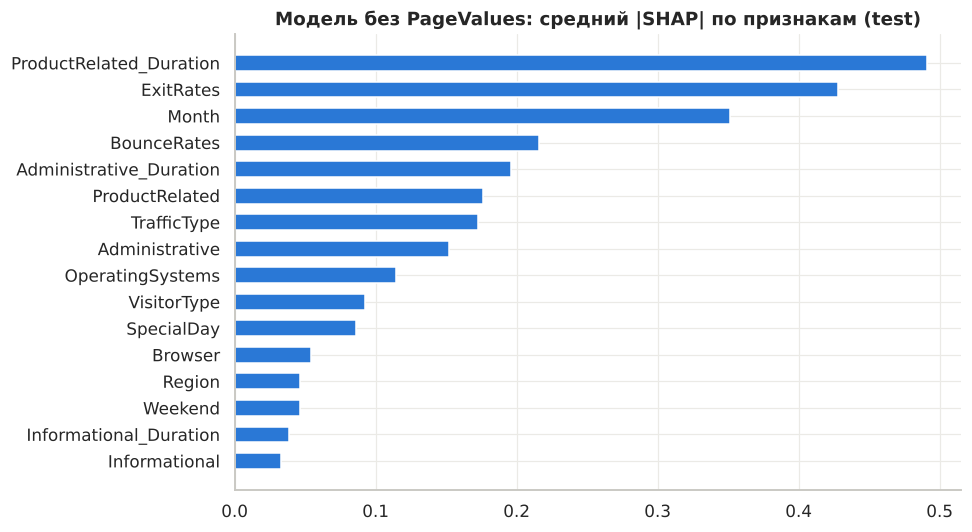

In [20]:
from sklearn.compose import ColumnTransformer
cols_wo = [c for c in X_train.columns if c != "PageValues"]
final_wo = Pipeline([("pre", make_preprocessor("tree")), ("clf", make_final_model())])
# тот же конвейер, но признак PageValues обнулён (константа не несёт информации)
Xtr_wo, Xte_wo = X_train.assign(PageValues=0.0), X_test.assign(PageValues=0.0)
oof_wo = cross_val_predict(final_wo, Xtr_wo, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
final_wo.fit(Xtr_wo, y_train)
p_wo = final_wo.predict_proba(Xte_wo)[:, 1]
cmp = pd.DataFrame({
    "с PageValues": [roc_auc_score(y_train, oof), average_precision_score(y_train, oof),
                     roc_auc_score(y_test, p_test), average_precision_score(y_test, p_test)],
    "без PageValues": [roc_auc_score(y_train, oof_wo), average_precision_score(y_train, oof_wo),
                       roc_auc_score(y_test, p_wo), average_precision_score(y_test, p_wo)],
}, index=["ROC-AUC (CV)", "PR-AUC (CV)", "ROC-AUC (test)", "PR-AUC (test)"])
cmp["разница"] = cmp["без PageValues"] - cmp["с PageValues"]
display(cmp.round(3))

Xwo_raw = final_wo.named_steps["pre"].transform(Xte_wo)
sv_wo = shap.TreeExplainer(final_wo.named_steps["clf"])(Xwo_raw)
Xwo_enc = Xwo_raw.copy(); Xwo_enc.columns = pretty_names(Xwo_raw.columns)
g_wo = pd.DataFrame({g: sv_wo.values[:, [Xwo_enc.columns.get_loc(c) for c in cols]].sum(axis=1)
                     for g, cols in groups.items() if g != "PageValues"}).abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(g_wo.index, g_wo.values, color=viz.BLUE, height=0.6)
ax.set_title("Модель без PageValues: средний |SHAP| по признакам (test)")
plt.tight_layout(); plt.show()

**Без `PageValues` качество падает радикально:** ROC-AUC 0,932 → 0,779 на CV и 0,929 → 0,765 на тесте, PR-AUC 0,740 → 0,360 и 0,744 → 0,355. Модель без этого признака всё ещё лучше случайной (PR-AUC 0,36 против 0,155), но разница огромна. В модели без `PageValues` на первые места выходят `ProductRelated_Duration`, `ExitRates`, `Month` и `BounceRates`.

**Что это значит.** Почти всё качество модели держится на одном признаке, который рассчитывается Google Analytics по доходу от транзакций. Если модель нужна для прогноза **в реальном времени** до оформления заказа, нужно проверить, как именно и когда считается `PageValues` для текущей сессии: если в нём уже «зашита» информация о покупке, честное качество ближе ко второму столбцу таблицы. В рамках учебного датасета признак оставлен в модели (он есть в исходных данных и в описании задачи UCI), но это главное ограничение результата.

## 9. Итоги

**Итоги lab5.**
1. Построены и настроены на 5-кратной кросс-валидации 8 вариантов моделей: Dummy, kNN, логистическая регрессия (плюс варианты с весами классов и SMOTE), решающее дерево, случайный лес, SVM, CatBoost.
2. Лучшие по PR-AUC на CV — случайный лес (0,748) и CatBoost (0,741), они неразличимы с учётом разброса; финальная модель — CatBoost без весов классов: лучшая калибровка вероятностей и лучший ROC-AUC.
3. На тесте финальная модель: ROC-AUC 0,929, PR-AUC 0,744; при пороге 0,27 (выбран по F1 на out-of-fold прогнозах train) — precision 0,61, recall 0,75, F1 0,675.
4. Качество словами: модель хорошо ранжирует сессии и выделяет группу, где покупка встречается в 4 раза чаще среднего, но пропускает четверть покупок, неотличимых по признакам от обычных сессий.
5. Интерпретация (коэффициенты, перестановочная важность, SHAP) согласованно показывает: главный признак — `PageValues`, затем месяц и поведенческие метрики (`ExitRates`, `BounceRates`, число и длительность просмотров). Без `PageValues` PR-AUC падает с 0,74 до 0,36 — это главное ограничение модели.

Финальная модель зафиксирована в `src/model.py`; её результаты (`results/`) показывает дашборд из lab6.